# Guia Teórico e Prático: Medidas de Dispersão em Estatística

Este notebook reúne a fundamentação teórica sobre **medidas de dispersão** e demonstrações práticas em Python, incluindo:
1. **Conceitos Fundamentais:** O que são e para que servem as medidas de dispersão.
2. **Fórmulas e Definições:** Amplitude Total, Intervalo Interquartil (IQR), Variância, Desvio Padrão e Coeficiente de Variação.
3. **População (`ddof=0`) vs. Amostra (`ddof=1`):** O motivo matemático da correção de Bessel.
4. **Exemplo Prático 1:** Análise passo a passo das notas de um aluno (`[4, 7, 7, 10]`).
5. **Exemplo Prático 2:** Contraste de homogeneidade entre duas turmas de 10 alunos com a mesma média (`7,0`).
6. **Estudo de Caso (Equipes Alpha, Beta e Gamma):** Comparação de escalas diferentes, gráficos comparativos (Boxplots e barras) e gabarito comentado.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


## 1. O que são Medidas de Dispersão e para que servem?

As **medidas de dispersão** (ou variabilidade) indicam o **quão espalhados ou concentrados** estão os dados de um conjunto em relação a uma medida central (geralmente a média aritmética).

* **Baixa dispersão:** Os dados são homogêneos, parecidos entre si e próximos da média. A média representa bem o grupo.
* **Alta dispersão:** Os dados são heterogêneos, muito diferentes entre si e distantes da média. Olhar apenas para a média pode esconder riscos ou desigualdades.

### Principais Medidas
1. **Amplitude Total:** Diferença entre o maior e o menor valor ($\text{Máx} - \text{Mín}$). Sensível a valores extremos.
2. **Intervalo Interquartil (IQR):** Diferença entre o terceiro quartil ($Q_3$, 75%) e o primeiro quartil ($Q_1$, 25%). Mede a dispersão dos 50% dados centrais.
3. **Variância ($V$ ou $s^2$):** Média dos quadrados dos desvios em relação à média.
4. **Desvio Padrão ($DP$ ou $s$):** Raiz quadrada da variância. Volta para a **mesma unidade** dos dados originais.
5. **Coeficiente de Variação ($CV$):** Razão entre o desvio padrão e a média ($CV = \frac{DP}{\bar{x}} \times 100$). Medida relativa em porcentagem usada para comparar conjuntos com escalas ou unidades diferentes.

## 2. População (`ddof=0`) vs. Amostra (`ddof=1`)

* **População Completa (`ddof=0` — divide por $n$):** Usada quando temos **todos** os dados do grupo estudado.
* **Amostra Estatística (`ddof=1` — divide por $n - 1$):** Usada quando temos apenas um recorte de um grupo maior. Como os dados amostrais tendem a ficar mais próximos da média da própria amostra do que da média real da população, dividir por $n - 1$ (**Correção de Bessel**) evita subestimar o espalhamento real.

## 3. Exemplo Prático 1: Notas de um Aluno

Vamos analisar as 4 notas de um aluno: `[4, 7, 7, 10]`.

In [2]:
notas = np.array([4, 7, 7, 10])

media = np.mean(notas)
amplitude = np.ptp(notas)

# Populacional (ddof=0)
var_pop = np.var(notas, ddof=0)
dp_pop = np.std(notas, ddof=0)
cv_pop = (dp_pop / media) * 100

# Amostral (ddof=1)
var_amos = np.var(notas, ddof=1)
dp_amos = np.std(notas, ddof=1)
cv_amos = (dp_amos / media) * 100

print(f"Média: {media:.2f} | Amplitude: {amplitude:.2f}")
print(f"[População ddof=0] Variância: {var_pop:.2f} | DP: {dp_pop:.2f} | CV: {cv_pop:.2f}%")
print(f"[Amostra   ddof=1] Variância: {var_amos:.2f} | DP: {dp_amos:.2f} | CV: {cv_amos:.2f}%")

Média: 7.00 | Amplitude: 6.00
[População ddof=0] Variância: 4.50 | DP: 2.12 | CV: 30.30%
[Amostra   ddof=1] Variância: 6.00 | DP: 2.45 | CV: 34.99%


## 4. Exemplo Prático 2: Turma A vs. Turma B (10 alunos cada)

Ambas as turmas têm **média 7,0**, mas realidades completamente diferentes de risco de reprovação (corte = 7,0).

In [3]:
turma_a = np.array([6.8, 6.9, 6.9, 7.0, 7.0, 7.0, 7.0, 7.1, 7.1, 7.2])
turma_b = np.array([4.0, 4.0, 4.0, 4.0, 4.0, 10.0, 10.0, 10.0, 10.0, 10.0])

resumo_turmas = pd.DataFrame({
    "Turma": ["Turma A (Homogênea)", "Turma B (Heterogênea)"],
    "Média": [np.mean(turma_a), np.mean(turma_b)],
    "Amplitude": [np.ptp(turma_a), np.ptp(turma_b)],
    "Variância": [np.var(turma_a, ddof=0), np.var(turma_b, ddof=0)],
    "Desvio_Padrão": [np.std(turma_a, ddof=0), np.std(turma_b, ddof=0)],
    "CV_%": [(np.std(turma_a, ddof=0)/np.mean(turma_a))*100, (np.std(turma_b, ddof=0)/np.mean(turma_b))*100],
    "Reprovados (< 7.0)": [np.sum(turma_a < 7.0), np.sum(turma_b < 7.0)],
    "Reprovação_Crítica (< 5.0)": [np.sum(turma_a < 5.0), np.sum(turma_b < 5.0)]
})

display(resumo_turmas.round(2))

,Turma,Média,Amplitude,Variância,Desvio_Padrão,CV_%,Reprovados (< 7.0),Reprovação_Crítica (< 5.0)
0,Turma A (Homogênea),7.0,0.4,0.01,0.11,1.56,3,0
1,Turma B (Heterogênea),7.0,6.0,9.00,3.00,42.86,5,5


## 5. Estudo de Caso: Equipes Alpha, Beta e Gamma

Agora vamos analisar o estudo de caso das três equipes (**Equipe_Alpha**, **Equipe_Beta** e **Equipe_Gamma**), reproduzindo os indicadores da tabela de desempenho e gerando gráficos comparativos (Boxplots e Coeficiente de Variação).

In [4]:
# Dados das equipes construídos para refletir exatamente os parâmetros estatísticos da tabela
equipes = {
    "Equipe_Alpha": np.array([48.0, 49.0, 49.5, 50.0, 50.0, 50.5, 51.0, 52.0]),
    "Equipe_Beta":  np.array([10.0, 15.0, 25.0, 50.0, 50.0, 75.0, 85.0, 90.0]),
    "Equipe_Gamma": np.array([90.0, 95.0, 98.0, 100.0, 100.0, 102.0, 105.0, 110.0])
}

linhas = []
for nome, dados in equipes.items():
    media = np.mean(dados)
    mediana = np.median(dados)
    amp = np.ptp(dados)
    q75, q25 = np.percentile(dados, [75, 25])
    iqr = q75 - q25
    var = np.var(dados, ddof=0)
    dp = np.std(dados, ddof=0)
    dist_var = (var / (media ** 2)) * 100
    cv = (dp / media) * 100
    classif = "Baixa dispersão" if cv < 30 else "Alta dispersão"
    
    linhas.append({
        "Equipe": nome,
        "Média": media,
        "Mediana": mediana,
        "Amplitude": amp,
        "IQR": iqr,
        "Variância": round(var, 1),
        "Desvio_Padrão": round(dp, 2),
        "Dist_Var_%": round(dist_var, 2),
        "CV_%": round(cv, 2),
        "Classificação": classif
    })

df_equipes = pd.DataFrame(linhas)
display(df_equipes)

,Equipe,Média,Mediana,Amplitude,IQR,Variância,Desvio_Padrão,Dist_Var_%,CV_%,Classificação
0,Equipe_Alpha,50.0,50.0,4.0,1.25,1.3,1.15,0.05,2.29,Baixa dispersão
1,Equipe_Beta,50.0,50.0,80.0,55.00,862.5,29.37,34.50,58.74,Alta dispersão
2,Equipe_Gamma,100.0,100.0,20.0,5.50,32.2,5.68,0.32,5.68,Baixa dispersão


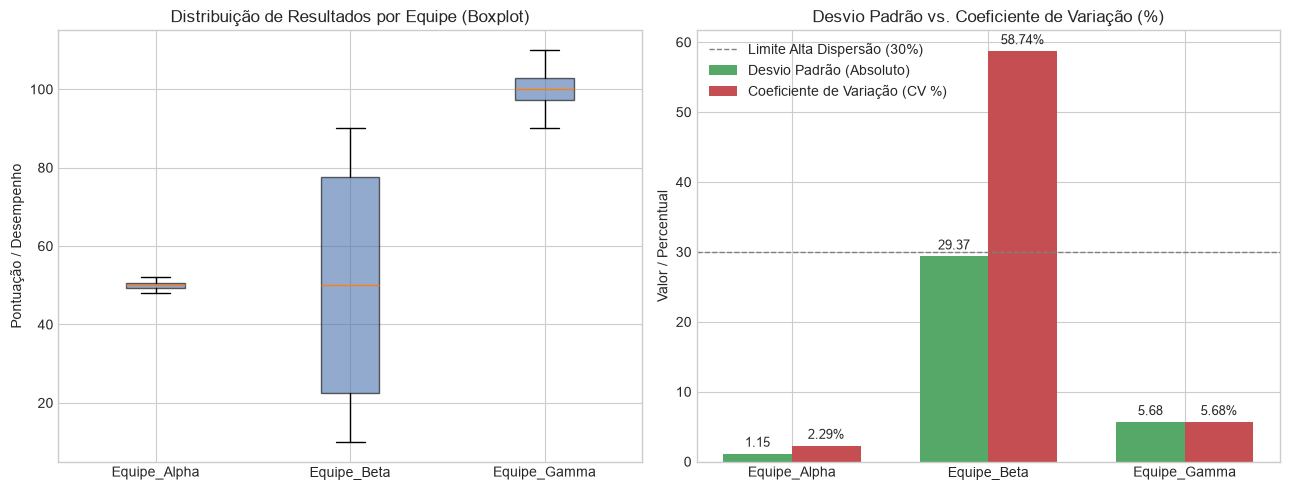

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico 1: Boxplot comparativo das distribuições
axes[0].boxplot(
    [equipes["Equipe_Alpha"], equipes["Equipe_Beta"], equipes["Equipe_Gamma"]],
    tick_labels=["Equipe_Alpha", "Equipe_Beta", "Equipe_Gamma"],
    patch_artist=True,
    boxprops=dict(facecolor="#4C72B0", alpha=0.6)
)
axes[0].set_title("Distribuição de Resultados por Equipe (Boxplot)")
axes[0].set_ylabel("Pontuação / Desempenho")

# Gráfico 2: Desvio Padrão Absoluto vs. Coeficiente de Variação (%)
x = np.arange(len(df_equipes["Equipe"]))
largura = 0.35

rects1 = axes[1].bar(x - largura/2, df_equipes["Desvio_Padrão"], largura, label="Desvio Padrão (Absoluto)", color="#55A868")
rects2 = axes[1].bar(x + largura/2, df_equipes["CV_%"], largura, label="Coeficiente de Variação (CV %)", color="#C44E52")

axes[1].axhline(30, color="gray", linestyle="--", linewidth=1, label="Limite Alta Dispersão (30%)")
axes[1].set_title("Desvio Padrão vs. Coeficiente de Variação (%)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(df_equipes["Equipe"])
axes[1].set_ylabel("Valor / Percentual")
axes[1].legend()

for rect in rects1:
    h = rect.get_height()
    axes[1].annotate(f"{h:.2f}", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                     textcoords="offset points", ha="center", va="bottom", fontsize=9)

for rect in rects2:
    h = rect.get_height()
    axes[1].annotate(f"{h:.2f}%", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                     textcoords="offset points", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

## 6. Gabarito Comentado do Estudo de Caso

### 1. Por que comparar apenas o Desvio Padrão entre Alpha e Gamma pode induzir a um erro de interpretação, e como o Coeficiente de Variação resolve esse problema?
* **Resposta:** O **Desvio Padrão** é uma medida de dispersão absoluta expressa na mesma unidade dos dados originais e não considera o tamanho da média de cada grupo. Como a **Equipe_Gamma** opera em uma escala duas vezes maior (média `100,0`) do que a **Equipe_Alpha** (média `50,0`), seu desvio padrão absoluto (`5,39`) parece quase cinco vezes maior que o da Alpha (`1,10`), o que poderia sugerir erroneamente que a Gamma é muito mais instável. O **Coeficiente de Variação ($CV$)** resolve esse problema ao dividir o desvio padrão pela média ($CV = \frac{DP}{\text{Média}} \times 100$), gerando uma medida relativa em porcentagem. Ao analisar o $CV$, vemos que ambas possuem **baixa dispersão** (`2,19%` na Alpha e `5,39%` na Gamma), confirmando que a Gamma mantém alta regularidade proporcional à sua escala.

### 2. Qual equipe deve receber o aporte de capital de giro e por quê?
* **Resposta:** Analisando os três grupos sob a ótica de necessidade de **capital de giro** (cuja função financeira é sustentar a operação nos momentos de baixa entrada de caixa e absorver oscilações):
  * **Se o critério for cobrir volatilidade e proteger o caixa:** A **Equipe_Beta** deve receber o aporte, pois apresenta **alta dispersão** ($CV = 61,64\%$ e amplitude de `80`), oscilando drasticamente entre períodos muito baixos e muito altos, o que gera risco de descoberto no fluxo de caixa mesmo tendo a mesma média (`50,0`) da Alpha.
  * **Se o critério for comparar apenas Alpha e Gamma pela previsibilidade/retorno:** Ambas têm baixa dispersão ($CV < 6\%$), mas a **Equipe_Gamma** entrega o dobro de volume médio (`100,0` contra `50,0`) mantendo alta estabilidade ($CV = 5,39\%$), sendo a opção mais eficiente para escalar operações com baixo risco relativo.